# WRF India classroom: your group, your computer

**One notebook for Google Colab and a local VS Code Python notebook.** It detects the supported runtime, finds the version-2 plotting kit and your assigned group archive, prepares an isolated plotting environment, safely extracts the files, and plots your group. The original TAR and NetCDF files are preserved.

Each student needs the **updated plotting-kit ZIP**, this notebook, and their **one assigned archive**:

| Group | Archive |
|---|---|
| 1 | `01_CTRL_lite.tar` |
| 2 | `02_CTRL_NOISE_lite.tar` |
| 3 | `03_CLEAN_lite.tar` |

**Colab:** put the ZIP and assigned TAR in your own `My Drive/WRF_Classroom` folder. Open this notebook in Colab. The notebook mounts your Drive with your authorization. It extracts the data and renders figures in the temporary runtime, then saves result ZIPs into your own Drive. Keep the TAR in Drive for later sessions.

**VS Code:** open the folder containing the notebook, updated kit ZIP and assigned TAR, then open this notebook. Select a working **64-bit Python 3.10+ kernel** (3.11 recommended) using the Python and Jupyter extensions. A notebook cannot install Python before a kernel starts. Once started, these cells prepare and use the plotting environment automatically.

Use a standard CPU runtime. Run the cells in order. **Run All makes a three-timestamp preview by default.** The complete-record cell has a separate switch to start the full analysis. No HPC account or password is needed.


## 1. Settings: normally leave these unchanged

With one group TAR in the recommended folder, leave `GROUP = None`. If several groups are present, set `GROUP = 1`, `2`, or `3`. An instructor with matching archives can use `GROUP = "all"`.

`DATA_HINT` and `KIT_HINT` are optional exact file/folder paths for an unusual location or an ambiguity. On Windows, use a raw string such as `r"D:\WRF_Classroom\01_CTRL_lite.tar"`. `MODE` can be `"full"` or `"surface"` if both products are available. No synthetic demo is selected automatically.


In [1]:
GROUP = 2         # Auto-detect one group, or set 1 / 2 / 3 / "all".
MODE = None          # Auto-detect, or set "full" / "surface".
DATA_HINT = ""       # Optional exact TAR path or extracted dataset folder.
KIT_HINT = ""        # Optional exact updated kit ZIP or extracted kit folder.


## 2. Detect the runtime and prepare a working folder

Colab asks you to authorize Drive access. Files visible only in **Shared with me** do not establish a path in your own My Drive: first upload/copy your assigned file into the folder above, or use an accessible shortcut and an exact `DATA_HINT`.

In Colab, the roughly 6 GiB group TAR stays in Drive while extraction and rendering use runtime disk. Only the result ZIPs are automatically copied back to Drive. Runtime resets remove the extracted copy and working figures; rerun this notebook to rebuild them from the TAR. In VS Code, the work folder remains on your computer.


In [2]:
from pathlib import Path, PurePosixPath
import hashlib, importlib.util, itertools, json, os, shutil, stat, subprocess, sys, tempfile, zipfile

try:
    _shell_module = type(get_ipython()).__module__
except NameError:
    _shell_module = ""
IN_COLAB = _shell_module.startswith("google.colab") or bool(os.environ.get("COLAB_RELEASE_TAG"))

if sys.version_info < (3, 10) or sys.maxsize <= 2**32:
    raise RuntimeError("Choose a working 64-bit Python 3.10+ notebook kernel; Python 3.11 is recommended.")

CWD = Path.cwd().resolve()
HOME = Path.home()
DRIVE_ROOT = None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    if not DRIVE_ROOT.is_dir():
        raise RuntimeError("Your Drive is not mounted. Complete the authorization and rerun this cell.")
    WORK_ROOT = Path("/content/WRF_Classroom_Work")
    RESULTS_HOME = DRIVE_ROOT / "WRF_Classroom" / "RESULTS"
else:
    _base = CWD if CWD != Path(CWD.anchor) else HOME / "WRF_Classroom"
    WORK_ROOT = _base / "WRF_Classroom_Work"
    try:
        WORK_ROOT.mkdir(parents=True, exist_ok=True)
        with tempfile.TemporaryFile(dir=WORK_ROOT):
            pass
    except OSError:
        WORK_ROOT = HOME / "WRF_Classroom" / "WRF_Classroom_Work"
    RESULTS_HOME = WORK_ROOT / "RESULTS"

WORK_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_HOME.mkdir(parents=True, exist_ok=True)
print("Runtime:", "Google Colab" if IN_COLAB else "local notebook / VS Code")
print("Notebook Python:", sys.executable)
print("Working folder:", WORK_ROOT)
print("Saved result ZIPs:", RESULTS_HOME)
print("Free working disk: %.1f GiB" % (shutil.disk_usage(WORK_ROOT).free / 2**30))


Runtime: local notebook / VS Code
Notebook Python: /usr/local/bin/python3
Working folder: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work
Saved result ZIPs: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/RESULTS
Free working disk: 235.2 GiB


## 3. Find the updated plotting kit

The search checks your current project, Downloads and usual `WRF_Classroom` folders with a depth/entry limit. It does not scan an entire computer or Drive. An old kit without the version-2 helper is rejected with an explanation. If several different valid kits are found, set `KIT_HINT` above and rerun the settings and this cell.


In [3]:
KIT_FILES = (
    "wrf_classroom.py", "wrf_data.py", "classroom_autodetect.py",
    "requirements.txt", "config.json", "cities.csv", "assets/coastline_india_region.json", "STUDENT_WORKFLOW_VERSION"
)
_skip = {".git", ".venv", "venv", "node_modules", "site-packages", "__pycache__",
         "demo_data", ".cache", "WRF_Classroom_Work", "test_deps", "drive"}

def bounded_directories(root, depth=3, limit=4000):
    root = Path(root).expanduser()
    if not root.is_dir():
        return
    queue, visited, count = [(root, 0)], set(), 0
    while queue and count < limit:
        folder, level = queue.pop(0)
        try:
            resolved = folder.resolve()
            if resolved in visited:
                continue
            visited.add(resolved)
            entries = sorted(itertools.islice(folder.iterdir(), limit - count), key=lambda x: x.name.lower())
            count += len(entries)
            yield folder, entries
            if level >= depth:
                continue
            for entry in entries:
                if entry.name in _skip or entry.name.startswith("."):
                    continue
                if entry.is_dir():
                    queue.append((entry, level + 1))
        except OSError:
            continue

def kit_signature(path):
    path = Path(path)
    try:
        if path.is_dir():
            if (path / "STUDENT_WORKFLOW_VERSION").read_text().strip() != "2":
                return None
            if any((path / name).stat().st_size > 8 * 1024**2 for name in KIT_FILES):
                return None
            contents = [(name, (path / name).read_bytes()) for name in KIT_FILES]
        else:
            with zipfile.ZipFile(path) as archive:
                members = archive.infolist()
                if len(members) > 5000 or sum(item.file_size for item in members) > 256 * 1024**2:
                    return None
                names = set(archive.namelist())
                prefixes = [name[:-len("STUDENT_WORKFLOW_VERSION")]
                            for name in names if name.endswith("STUDENT_WORKFLOW_VERSION")]
                prefixes = [prefix for prefix in prefixes
                            if all(prefix + name in names for name in KIT_FILES)
                            and archive.read(prefix + "STUDENT_WORKFLOW_VERSION").strip() == b"2"]
                if len(prefixes) != 1:
                    return None
                prefix = prefixes[0]
                contents = [(name, archive.read(prefix + name)) for name in KIT_FILES]
        digest = hashlib.sha256()
        for name, content in contents:
            digest.update(name.encode() + b"\0" + content)
        return digest.hexdigest()
    except (OSError, KeyError, ValueError, zipfile.BadZipFile):
        return None

def safe_zip_target(base, name):
    pure = PurePosixPath(name)
    if pure.is_absolute() or ".." in pure.parts or "\\" in name or ":" in name:
        raise ValueError("Unsafe kit ZIP path: " + name)
    target = (base / Path(*pure.parts)).resolve()
    if not target.is_relative_to(base.resolve()):
        raise ValueError("Kit ZIP path escapes its destination.")
    return target

def unpack_kit(path, signature):
    cache = WORK_ROOT / "kit_cache"
    destination = cache / signature[:20]
    if destination.is_dir():
        valid = [p.parent for p in destination.rglob("STUDENT_WORKFLOW_VERSION")
                 if kit_signature(p.parent) == signature]
        if len(valid) == 1:
            return valid[0]
        raise RuntimeError("An incomplete kit cache exists at %s. Set KIT_HINT to an intact extracted kit or choose a fresh work folder." % destination)
    cache.mkdir(parents=True, exist_ok=True)
    stage = Path(tempfile.mkdtemp(prefix="unpack_", dir=cache))
    try:
        with zipfile.ZipFile(path) as archive:
            members = archive.infolist()
            if len(members) > 5000 or sum(x.file_size for x in members) > 256 * 1024**2:
                raise ValueError("This ZIP exceeds the plotting-kit limit (256 MiB / 5000 members).")
            if sum(x.file_size for x in members) + 32 * 1024**2 > shutil.disk_usage(stage).free:
                raise OSError("Insufficient working disk for the plotting kit.")
            seen = set()
            for item in members:
                target = safe_zip_target(stage, item.filename)
                key = item.filename.rstrip("/").casefold()
                if key in seen:
                    raise ValueError("Duplicate kit ZIP member: " + item.filename)
                seen.add(key)
                kind = stat.S_IFMT(item.external_attr >> 16)
                if kind not in (0, stat.S_IFREG, stat.S_IFDIR):
                    raise ValueError("Links and special files are not accepted in the kit ZIP.")
                if item.is_dir():
                    target.mkdir(parents=True, exist_ok=True)
                else:
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with archive.open(item) as source, target.open("wb") as sink:
                        shutil.copyfileobj(source, sink, 1024 * 1024)
        valid = [p.parent for p in stage.rglob("STUDENT_WORKFLOW_VERSION")
                 if kit_signature(p.parent) == signature]
        if len(valid) != 1:
            raise ValueError("The ZIP must contain exactly one complete version-2 plotting kit.")
        relative = valid[0].relative_to(stage)
        checksums = valid[0] / "SHA256SUMS.json"
        if checksums.is_file():
            for name, expected in json.loads(checksums.read_text()).items():
                target = safe_zip_target(valid[0], name)
                if not target.is_file() or hashlib.sha256(target.read_bytes()).hexdigest() != expected:
                    raise ValueError("Kit checksum mismatch: " + name)
        stage.rename(destination)
        return destination / relative
    finally:
        if stage.exists():
            shutil.rmtree(stage)

if KIT_HINT:
    _hint = Path(KIT_HINT).expanduser()
    _candidates = [_hint]
    if _hint.is_dir() and not (_hint / "wrf_classroom.py").is_file():
        _candidates += [_hint / "wrf_classroom_kit"]
else:
    _roots = [(CWD, 3), (HOME / "Downloads", 3), (HOME / "WRF_Classroom", 3)]
    if CWD.parent != CWD and CWD.parent != Path(CWD.anchor):
        _roots.append((CWD.parent, 1))
    if DRIVE_ROOT is not None:
        _roots += [(DRIVE_ROOT / "WRF_Classroom", 3), (DRIVE_ROOT, 1)]
    _candidates = []
    for _root, _depth in _roots:
        for _folder, _entries in bounded_directories(_root, depth=_depth):
            if (_folder / "STUDENT_WORKFLOW_VERSION").is_file():
                _candidates.append(_folder)
            _candidates.extend(p for p in _entries if p.suffix.lower() == ".zip"
                               and ("classroom" in p.name.lower() or "plot_kit" in p.name.lower()))

_valid, _seen = [], set()
for _path in _candidates:
    try:
        _path = _path.resolve()
    except OSError:
        continue
    if _path in _seen:
        continue
    _seen.add(_path)
    _signature = kit_signature(_path)
    if _signature:
        _valid.append((_path, _signature))
if not _valid:
    raise FileNotFoundError("Updated plotting kit not found. Put the new version-2 WRF_India_Classroom_Plot_Kit.zip beside this notebook or in MyDrive/WRF_Classroom, or set KIT_HINT. The older kit lacks classroom_autodetect.py.")
if len({signature for _, signature in _valid}) != 1:
    for path, _ in _valid:
        print("Possible kit:", path)
    raise ValueError("Several different plotting kits were found. Set KIT_HINT to the intended ZIP/folder, rerun settings, then rerun this cell.")
_valid.sort(key=lambda item: (not item[0].is_dir(), len(str(item[0]))))
_chosen, _signature = _valid[0]
KIT = _chosen if _chosen.is_dir() else unpack_kit(_chosen, _signature)
print("Plotting kit:", KIT)


Plotting kit: /Users/nehapalak/Downloads/wrf_classroom_kit


## 4. Prepare the plotting environment automatically

Colab uses its current Python in fresh subprocesses. Local VS Code reuses a valid existing classroom Conda environment when available, or creates a private Python environment under the working folder. The selected notebook kernel remains unchanged. A working internet connection is needed the first time packages are installed.


In [4]:
CHILD_ENV = os.environ.copy()
CHILD_ENV.update(PYTHONUTF8="1", PYTHONIOENCODING="utf-8", MPLBACKEND="Agg")
requirements = KIT / "requirements.txt"
probe = r"""
import importlib, importlib.metadata, json, pathlib, sys
from packaging.requirements import Requirement
for line in pathlib.Path(sys.argv[1]).read_text().splitlines():
    line = line.strip()
    if not line or line.startswith('#'):
        continue
    req = Requirement(line)
    version = importlib.metadata.version(req.name)
    if version not in req.specifier:
        raise RuntimeError('%s %s does not meet %s' % (req.name, version, req.specifier))
for name in ('numpy', 'netCDF4', 'matplotlib', 'PIL', 'paramiko'):
    importlib.import_module(name)
print(json.dumps({name: importlib.metadata.version(name) for name in ('numpy','netCDF4','matplotlib','Pillow','paramiko')}))
"""

def environment_probe(prefix):
    return subprocess.run(prefix + ["-c", probe, str(requirements)],
                          capture_output=True, text=True, encoding="utf-8",
                          errors="replace", env=CHILD_ENV)

PLOT_PREFIX = None
if IN_COLAB:
    PLOT_PREFIX = [sys.executable]
else:
    runtime_file = KIT / ".runtime.json"
    if runtime_file.is_file():
        try:
            runtime = json.loads(runtime_file.read_text(encoding="utf-8-sig"))
            conda, prefix = Path(runtime["conda"]), Path(runtime["prefix"])
            if conda.is_file() and prefix.is_dir():
                candidate = [str(conda), "run", "--no-capture-output", "--prefix", str(prefix), "python"]
                if environment_probe(candidate).returncode == 0:
                    PLOT_PREFIX = candidate
                    print("Using the existing classroom Conda environment:", prefix)
        except (OSError, ValueError, KeyError):
            pass
    if PLOT_PREFIX is None:
        environment = WORK_ROOT / "runtime" / "python_env"
        interpreter = environment / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
        if not interpreter.is_file():
            print("Creating the private plotting environment:", environment)
            subprocess.run([sys.executable, "-m", "venv", str(environment)], check=True, env=CHILD_ENV)
        PLOT_PREFIX = [str(interpreter)]

checked = environment_probe(PLOT_PREFIX)
if checked.returncode != 0:
    print("Installing the plotting requirements; this can take several minutes...")
    subprocess.run(PLOT_PREFIX + ["-m", "pip", "install", "--disable-pip-version-check", "-q", "-r", str(requirements)],
                   check=True, env=CHILD_ENV)
    checked = environment_probe(PLOT_PREFIX)
    if checked.returncode != 0:
        print(checked.stdout)
        print(checked.stderr)
        raise RuntimeError("The plotting environment failed its import/version check. Read the error above; choose a working Python 3.11 kernel locally if necessary.")
print("Plotting environment ready:", checked.stdout.strip())
(WORK_ROOT / "resolved_plotting_packages.json").write_text(checked.stdout, encoding="utf-8")


Creating the private plotting environment: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/runtime/python_env
Installing the plotting requirements; this can take several minutes...
Plotting environment ready: {"numpy": "2.5.5", "netCDF4": "1.7.5.1.post1", "matplotlib": "3.11.2", "Pillow": "12.3.0", "paramiko": "4.0.0"}


112

## 5. Detect and prepare your assigned group

The archive contains metadata for the instructor's three-group export. The helper preserves that provenance and creates a **selected-group view** with the expected records for your group. A group-1 student should see **41 ready snapshots**, not 123. Missing groups are not treated as missing files in your assigned work.

The helper streams TAR extraction and checks file sizes. It rejects unsafe archive paths, links and incomplete exports. It can resume completed extracted files on a rerun. Keep the TAR unchanged. An extracted input folder can also be detected. Multiple different cases/runs require an explicit choice rather than a silent guess.


In [5]:
spec = importlib.util.spec_from_file_location("classroom_autodetect", KIT / "classroom_autodetect.py")
student_data = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = student_data
spec.loader.exec_module(student_data)
if getattr(student_data, "WORKFLOW_VERSION", None) != 2:
    raise RuntimeError("This notebook needs the version-2 classroom data helper.")

search_roots = [CWD, KIT.parent, HOME / "Downloads", HOME / "WRF_Classroom"]
if DRIVE_ROOT is not None:
    search_roots.insert(0, DRIVE_ROOT / "WRF_Classroom")
search_roots = list(dict.fromkeys(p.resolve() for p in search_roots if p.is_dir()))

candidates = student_data.discover_student_data(
    search_roots, group=GROUP, data_hint=DATA_HINT or None, mode=MODE or None
)
for warning in getattr(student_data, "DISCOVERY_WARNINGS", []):
    print("Discovery note:", warning)
if not candidates:
    raise FileNotFoundError("No eligible real dataset was found. Put your assigned *_lite.tar beside the notebook or in your own MyDrive/WRF_Classroom. For another location, set DATA_HINT to the exact file/folder and rerun the settings and this cell.")
if len(candidates) > 1:
    for index, candidate in enumerate(candidates, 1):
        print(index, candidate.get("label", candidate.get("path")), candidate.get("path", ""))
    raise ValueError("Several eligible datasets were found. Set GROUP to your assigned number, MODE if needed, or DATA_HINT to the exact intended file/folder. Rerun settings and this cell.")

prepared = student_data.prepare_student_dataset(candidates[0], work_root=WORK_ROOT)
DATA_ROOTS = [str(prepared["data_root"])]
OUTPUT_BASE = Path(prepared["output_root"])
EXPECTED_RECORDS = int(prepared["expected_records"])
SELECTED_CASES = list(prepared.get("cases") or [prepared["case"]])
DATA_MODE = prepared["mode"]
for warning in prepared.get("warnings", []):
    print("Data note:", warning)
print("Selected groups:", ", ".join(SELECTED_CASES))
print("Mode:", DATA_MODE)
print("Expected records for this selection:", EXPECTED_RECORDS)
print("Input view:", DATA_ROOTS[0])
print("Figure folders:", OUTPUT_BASE)


Prepared wrflite_d01_2023-06-22_00-00-00.nc (1 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_03-00-00.nc (2 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_06-00-00.nc (3 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_09-00-00.nc (4 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_12-00-00.nc (5 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_15-00-00.nc (6 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_18-00-00.nc (7 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-22_21-00-00.nc (8 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-23_00-00-00.nc (9 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-23_03-00-00.nc (10 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-23_06-00-00.nc (11 / 41 newly needed for this group)
Prepared wrflite_d01_2023-06-23_09-00-00.nc (12 / 41 newly needed for this group)
Prepared wrflite_d01_2023

## 6. Inspect the real data before plotting

This opens the selected NetCDF headers and samples, checks actual completeness, and reports city coverage. A nearest model grid cell represents each city; it is not a city-wide observational average. Cities outside the model grid remain unavailable.


In [6]:
def engine(action, *extra, output=None, capture=False):
    command = PLOT_PREFIX + [str(KIT / "wrf_classroom.py"), action, "--data", *DATA_ROOTS]
    if action != "inspect":
        command += ["--output", str(output if output is not None else ACTIVE_OUTPUT)]
    command += [str(value) for value in extra]
    result = subprocess.run(command, capture_output=capture, text=True, encoding="utf-8",
                            errors="replace", env=CHILD_ENV, cwd=str(KIT))
    if result.returncode:
        if capture:
            print(result.stdout)
            print(result.stderr)
        raise RuntimeError("The plotting engine stopped with exit code %d. Read its message above." % result.returncode)
    return result

inspection = json.loads(engine("inspect", capture=True).stdout)
status = inspection["status"]
print(json.dumps(status, indent=2))
for warning in inspection.get("warnings", []):
    print("Inspection note:", warning)
if status.get("complete") is not True or status.get("ready_records") != EXPECTED_RECORDS:
    raise RuntimeError("The selected group is not locally complete. Resolve the inspection notes before plotting.")
if status.get("deferred_files", 0) or status.get("duplicate_records", 0):
    raise RuntimeError("Deferred or duplicate records remain; inspect the messages above.")
for sample in inspection["samples"]:
    if sample.get("synthetic"):
        raise RuntimeError("Synthetic data was found. Select the real assigned group archive.")
    if sample.get("missing_fields"):
        raise RuntimeError("Missing primary fields: " + ", ".join(sample["missing_fields"]))
    print("\n", sample["case"], sample["mode"], "grid", sample["grid_shape"])
    for city in sample.get("city_coverage", []):
        print("  %-12s %-15s levels=%s height=%s" %
              (city["name"], city["status"], city["levels"], city["height_available"]))
print("\nReady:", EXPECTED_RECORDS, "snapshots for", ", ".join(SELECTED_CASES))


{
  "ready_files": 41,
  "ready_records": 41,
  "deferred_files": 0,
  "duplicate_records": 0,
  "standalone_files": 0,
  "manifests": [
    {
      "path": "/Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/data/full_g2_acd8e62a78_7dbe26dc/manifest.json",
      "complete": true,
      "planned_files": 41,
      "listed_files": 41,
      "local_ready_files": 41,
      "classroom_scope": {
        "kind": "selected_cases",
        "selected_cases": [
          "02_CTRL_NOISE"
        ],
        "parent_manifest_sha256": "7dbe26dce1f3cd4bccfcbc6b2c23973d362f390b8d472afe6be46654b9fa49b9",
        "parent_manifest_file": "provenance/source_manifest.json",
        "parent_complete": true,
        "parent_planned_files": 123,
        "parent_config_hash": "acd8e62a7838cda6ea767eb6c954228d2ebd1e7e7dedab885023ced13a555957"
      },
      "selected_cases": [
        "02_CTRL_NOISE"
      ]
    }
  ],
  "complete": true,
  "completion_scope": "selected_cases",
  "scope_cases": [
  

## 7. Make the preview and save it

The preview uses **PM2.5, SO2, total rainfall rate and wind speed**, with three timestamps per selected group. Full-level files also produce the available PM2.5/SO2 vertical figures. The first rain-rate frame is unavailable because a previous accumulated-rain value is needed.

The result ZIP contains plots and numerical tables, not your input data or rendering caches. In Colab it is copied automatically into your own `MyDrive/WRF_Classroom/RESULTS`. Keep the notebook running until the save message appears.


In [7]:
def check_run(output, complete_record=False):
    status = json.loads((Path(output) / "data_status.json").read_text(encoding="utf-8"))
    if status.get("errors"):
        print(json.dumps(status["errors"], indent=2))
        raise RuntimeError("Some selected snapshots failed. Resolve these errors before treating the run as complete.")
    if status.get("source_complete") is not True or status.get("available_records") != EXPECTED_RECORDS:
        raise RuntimeError("The input changed or is no longer complete for the selected groups.")
    if status.get("processed_records") != status.get("selected_records") or not status.get("processed_records"):
        raise RuntimeError("Not all selected snapshots were processed.")
    if complete_record and (status.get("preview") or status["processed_records"] != EXPECTED_RECORDS):
        raise RuntimeError("This is not a complete-record result.")
    print("Processed:", status["processed_records"], "/", status["selected_records"], "selected snapshots")
    print("Fields:", ", ".join(status["fields"]))
    print("Gallery:", Path(output) / "index.html")
    return status

def save_result_zip(output, label):
    case_label = "_".join(SELECTED_CASES)
    name = "WRF_%s_%s_%s_Plots.zip" % (case_label, DATA_MODE, label)
    local_archive = WORK_ROOT / name
    command = PLOT_PREFIX + [str(KIT / "wrf_classroom.py"), "package",
                            "--output", str(output), "--archive", str(local_archive)]
    subprocess.run(command, check=True, env=CHILD_ENV, cwd=str(KIT))
    destination = RESULTS_HOME / name
    temporary = destination.with_name(destination.name + ".part")
    with local_archive.open("rb") as source, temporary.open("wb") as sink:
        shutil.copyfileobj(source, sink, 1024 * 1024)
    os.replace(temporary, destination)
    print("Saved result ZIP:", destination)
    return destination

PREVIEW_FIELDS = "PM2_5_DRY,so2,RAIN_RATE,WIND_SPEED"
ACTIVE_OUTPUT = OUTPUT_BASE / "preview"
engine("run", "--fields", PREVIEW_FIELDS, "--max-frames", "3", output=ACTIVE_OUTPUT)
PREVIEW_STATUS = check_run(ACTIVE_OUTPUT)
LATEST_ZIP = save_result_zip(ACTIVE_OUTPUT, "preview")


Rendered 1/3: full / 02_CTRL_NOISE / 2023-06-22_00-00-00
Rendered 2/3: full / 02_CTRL_NOISE / 2023-06-22_03-00-00
Rendered 3/3: full / 02_CTRL_NOISE / 2023-06-22_06-00-00
Updating city tables and comparison figures...


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Ready: 3/3 selected snapshots. Open /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/preview/index.html
Processed: 3 / 3 selected snapshots
Fields: PM2_5_DRY, so2, RAIN_RATE, WIND_SPEED
Gallery: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/preview/index.html
Saved shareable results: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/WRF_02_CTRL_NOISE_full_preview_Plots.zip (3.7 MiB)
Saved result ZIP: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/RESULTS/WRF_02_CTRL_NOISE_full_preview_Plots.zip


## 8. Plot the complete record: all fields or your own selection

After checking the preview, change **`RUN_FULL = True` in the following cell** and run that cell. You do not need to repeat extraction or setup.

Leave `FULL_FIELDS = ""` to plot all 20 primary fields plus wind speed and three rainfall-rate products. To choose your own figures, use a comma-separated list, for example:

- Pollution: `PM2_5_DRY,PM10,TOT_DUST,so2,BC1,OC1`
- Weather: `T2,Q2,PSFC,U10,V10,WIND_SPEED`
- Rainfall rates: `RAIN_RATE,RAINC_RATE,RAINNC_RATE`

Field names are case-sensitive. A complete-record run uses all available times for the chosen fields. The six atmospheric fields support vertical products with full input; the fourteen native surface fields do not have atmospheric profiles in this subset. The full input already supplies surface maps, so no additional surface archive is needed.


In [8]:
RUN_FULL = True    # Change to True after reviewing the preview.
FULL_FIELDS = ""   # Blank = all 20 primary fields and four derived products.

if RUN_FULL:
    ACTIVE_OUTPUT = OUTPUT_BASE / "complete"
    arguments = ["--fields", FULL_FIELDS] if FULL_FIELDS.strip() else []
    engine("run", *arguments, output=ACTIVE_OUTPUT)
    FULL_STATUS = check_run(ACTIVE_OUTPUT, complete_record=True)
    LATEST_ZIP = save_result_zip(ACTIVE_OUTPUT, "complete")
else:
    print("Preview finished. Set RUN_FULL = True in this cell to process the complete record.")


Rendered 1/41: full / 02_CTRL_NOISE / 2023-06-22_00-00-00
Rendered 2/41: full / 02_CTRL_NOISE / 2023-06-22_03-00-00
Rendered 3/41: full / 02_CTRL_NOISE / 2023-06-22_06-00-00
Rendered 4/41: full / 02_CTRL_NOISE / 2023-06-22_09-00-00
Rendered 5/41: full / 02_CTRL_NOISE / 2023-06-22_12-00-00
Rendered 6/41: full / 02_CTRL_NOISE / 2023-06-22_15-00-00
Rendered 7/41: full / 02_CTRL_NOISE / 2023-06-22_18-00-00
Rendered 8/41: full / 02_CTRL_NOISE / 2023-06-22_21-00-00
Rendered 9/41: full / 02_CTRL_NOISE / 2023-06-23_00-00-00
Rendered 10/41: full / 02_CTRL_NOISE / 2023-06-23_03-00-00
Rendered 11/41: full / 02_CTRL_NOISE / 2023-06-23_06-00-00
Rendered 12/41: full / 02_CTRL_NOISE / 2023-06-23_09-00-00
Rendered 13/41: full / 02_CTRL_NOISE / 2023-06-23_12-00-00
Rendered 14/41: full / 02_CTRL_NOISE / 2023-06-23_15-00-00
Rendered 15/41: full / 02_CTRL_NOISE / 2023-06-23_18-00-00
Rendered 16/41: full / 02_CTRL_NOISE / 2023-06-23_21-00-00
Rendered 17/41: full / 02_CTRL_NOISE / 2023-06-24_00-00-00
Render

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Ready: 41/41 selected snapshots. Open /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/complete/index.html
Processed: 41 / 41 selected snapshots
Fields: T2, Q2, PSFC, U10, V10, TSK, PBLH, HFX, LH, SWDOWN, GLW, RAINC, RAINNC, GRDFLX, PM2_5_DRY, PM10, TOT_DUST, BC1, so2, OC1, WIND_SPEED, RAINC_RATE, RAINNC_RATE, RAIN_RATE
Gallery: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/complete/index.html
Saved shareable results: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/WRF_02_CTRL_NOISE_full_complete_Plots.zip (141.4 MiB)
Saved result ZIP: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/RESULTS/WRF_02_CTRL_NOISE_full_complete_Plots.zip


## 9. View and collect your plots

The cell below displays a few current results. In VS Code, open the printed `index.html` in your browser for the complete gallery. In Colab, download the saved result ZIP from your Drive and extract it to view the complete gallery locally, or inspect the images and CSV tables directly in the runtime. Keep `index.html` together with its subfolders when sharing a gallery.

Output folders include `maps`, `city_timeseries`, `city_vertical` and `profile_animations` where supported. Numerical values, actual times, units and sampled city grid locations are in `tables`. Colab's temporary working files do not survive a runtime reset; the saved Drive result ZIP does.


Current figures: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/complete
Gallery: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/complete/index.html
Numerical tables: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/results/full_g2_acd8e62a78_7dbe26dc/complete/tables
Saved ZIP: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/RESULTS/WRF_02_CTRL_NOISE_full_complete_Plots.zip
maps/full/02_CTRL_NOISE/BC1.gif


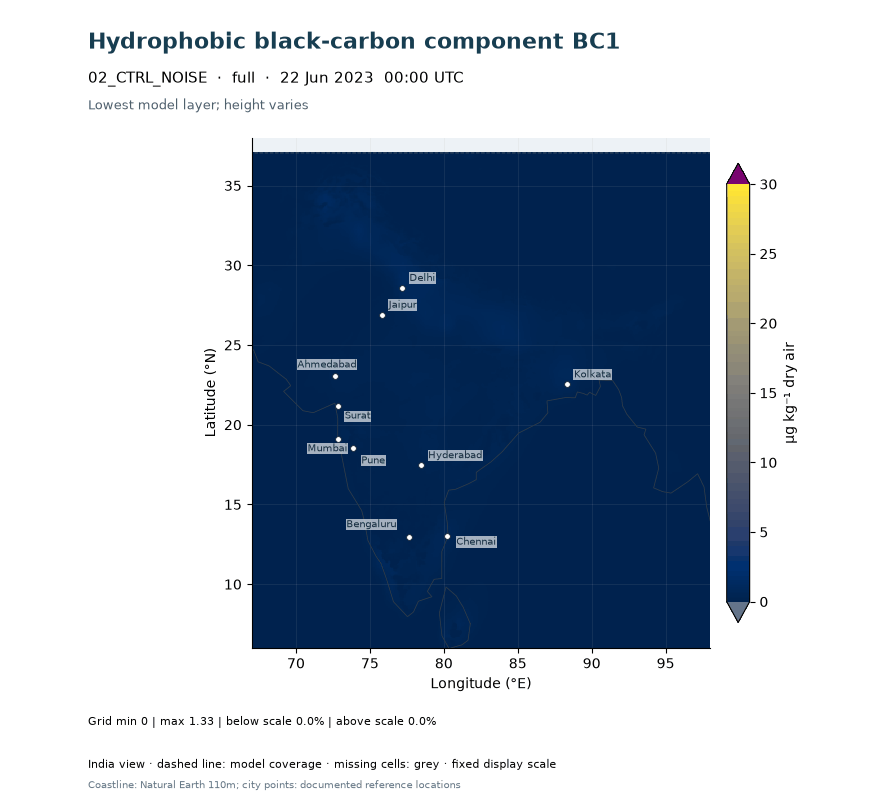

maps/full/02_CTRL_NOISE/GLW.gif


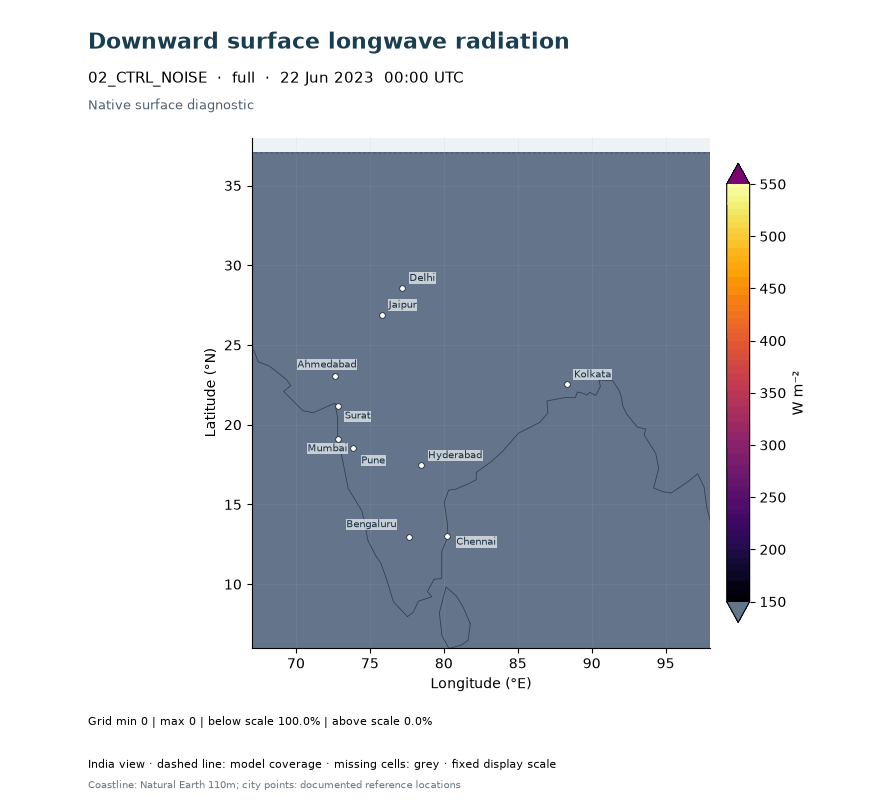

city_timeseries/full/BC1.png


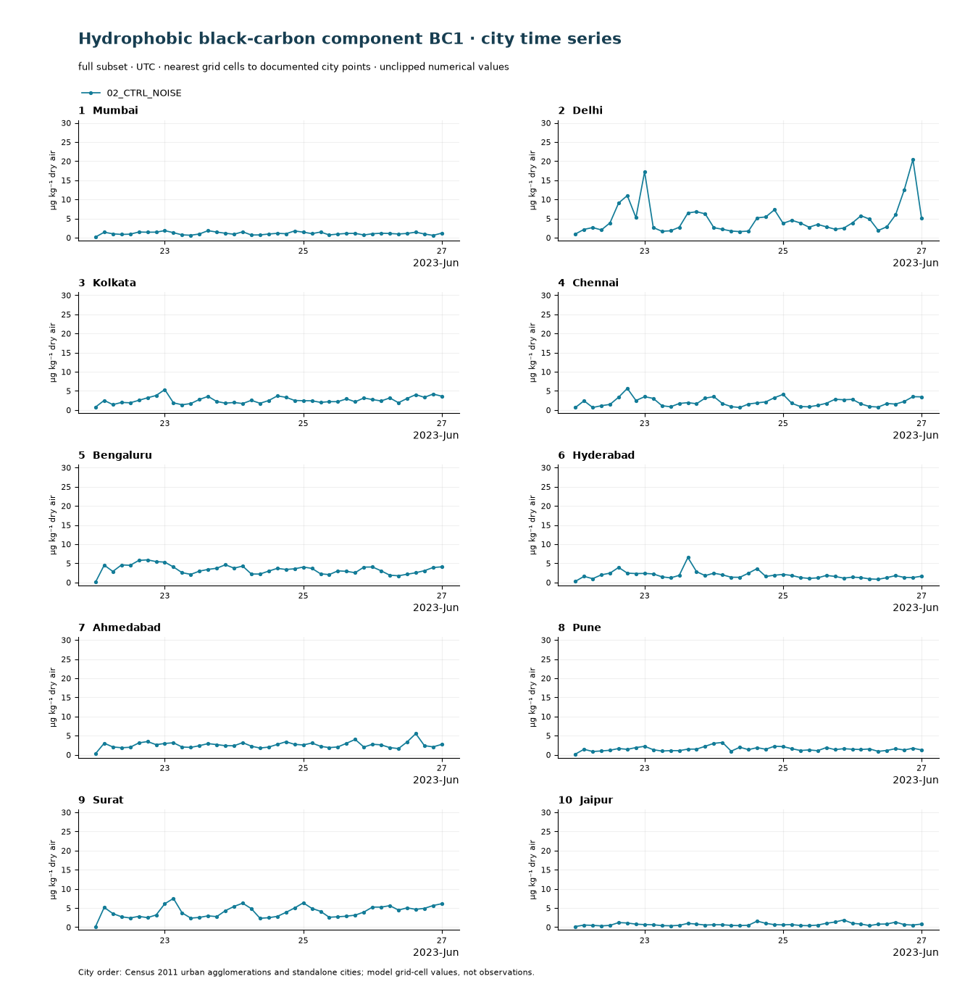

city_vertical/ahmedabad/BC1.png


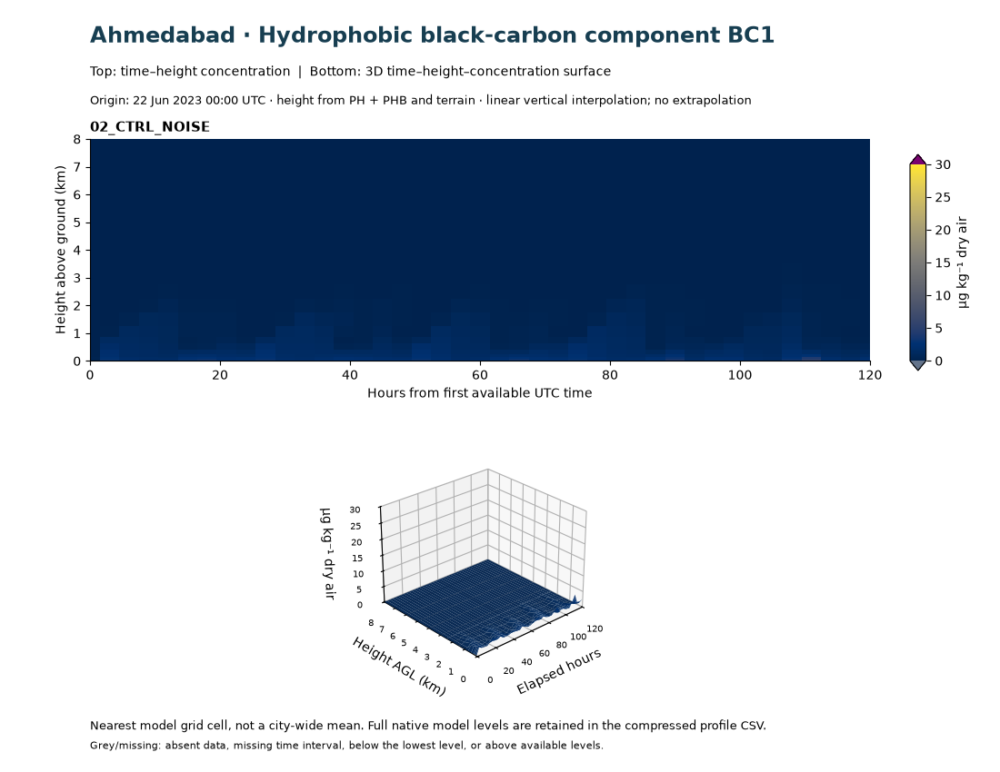

In [9]:
from IPython.display import Image, display
print("Current figures:", ACTIVE_OUTPUT)
print("Gallery:", ACTIVE_OUTPUT / "index.html")
print("Numerical tables:", ACTIVE_OUTPUT / "tables")
print("Saved ZIP:", LATEST_ZIP)
for folder, pattern, count in (("maps", "*.gif", 2),
                               ("city_timeseries", "*.png", 1),
                               ("city_vertical", "*.png", 1)):
    for path in sorted((ACTIVE_OUTPUT / folder).rglob(pattern))[:count]:
        print(path.relative_to(ACTIVE_OUTPUT))
        display(Image(filename=str(path), width=800))


### Optional: download the result ZIP directly from Colab

Drive already has a persistent copy. Set the switch only if you also want a browser download now. Local VS Code users can open the printed results folder.


In [11]:
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(str(LATEST_ZIP))
elif DOWNLOAD_RESULTS:
    print("Open this local file:", LATEST_ZIP)


Open this local file: /Users/nehapalak/Downloads/wrf_classroom_kit/WRF_Classroom_Work/RESULTS/WRF_02_CTRL_NOISE_full_complete_Plots.zip


## Interpretation and practical limits

- This is the **22–27 June 2023 simulation**, when using the supplied full class export. The dataset's internal timestamps determine every figure. They are not today's weather.
- PM2.5 uses a 0–400 micrograms/m3 display, not an AQI calculation. Wind-speed maps use 0–25 m/s; values beyond the display limits receive an over-range colour.
- Rainfall-rate colours have boundaries 0, 0.1, 0.5, 1, 2, 5, 10 and 15 mm/hour. With three-hour input these are preceding-interval mean rates, not recovered hourly peaks. `RAINC` and `RAINNC` remain accumulated millimetres.
- SO2 is displayed in ppbv. BC1 and OC1 retain micrograms/kg dry-air units and are individual aerosol components. Q2 is a mixing ratio; PSFC is surface pressure.
- Physical-height plots need PH, PHB and HGT. The 3D figure axes are time, height above ground and concentration at a city's model column. The default figure shows up to 8 km AGL; all retained native levels remain in the profile table.
- The city selection uses the documented Census 2011 population basis. Coverage is checked against the actual grid. One-group runs show your experiment; between-group comparisons require corresponding additional archives and an explicit selection.
- The notebook can detect files it can access in the supported locations. It cannot obtain access to another person's private Drive, find arbitrary remote files without a path, install a VS Code kernel before Python starts, or bypass Drive authorization and storage/runtime limits.

See the included `STUDENT_NOTEBOOK_GUIDE.txt`, `SCIENCE.md`, `SOURCES.md` and `config.json` for the workflow, references and scales.

Primary software references: [Colab FAQ](https://research.google.com/colaboratory/faq.html), [VS Code Python notebooks](https://code.visualstudio.com/docs/datascience/jupyter-notebooks), [Python virtual environments](https://docs.python.org/3/library/venv.html), and [WRF output variables](https://www2.mmm.ucar.edu/wrf/site/users_guide/output_variables.html).
